# UTS Graf Sains Data — Sistem Rekomendasi dengan Neo4j dan Python

**Nama** : Astrid Septya Regita P.  
**NIM**  : 24031554171

**Kombinasi periode (no. 31)**
- P1 (Training) : 16 – 31 Juli 2015 (UTC)
- P2 (Testing)  : 01 – 15 Agustus 2015 (UTC)

## 0. Persiapan

In [1]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import neo4j
from neo4j import GraphDatabase, RoutingControl
from sklearn.preprocessing import normalize
from IPython.display import display, Markdown

print("Versi driver neo4j:", neo4j.__version__)   # harus 5.x

# --- Konfigurasi koneksi (password dibaca dari environment variable, jangan ditulis di notebook) ---
URI      = os.getenv("NEO4J_URI", "neo4j://127.0.0.1:7687")
USER     = os.getenv("NEO4J_USER", "neo4j")
PASSWORD = os.getenv("NEO4J_PASSWORD", "Regita804")
DB       = "neo4j"

# --- Seed untuk proses acak yang bisa direproduksi (boleh diganti, misal 2 digit akhir NIM) ---
SEED = 71

def fmt(n):
    """Format angka ribuan ala Indonesia: 1234567 -> 1.234.567"""
    return f"{int(n):,}".replace(",", ".")

Versi driver neo4j: 6.4.1


In [2]:
driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

def run_query(query, **params):
    records, _, _ = driver.execute_query(query, database_=DB, **params)
    return pd.DataFrame([r.data() for r in records])

try:
    driver.verify_connectivity()
    print("Berhasil terhubung ke Neo4j!")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")

Berhasil terhubung ke Neo4j!


## 1. Tugas Pendahuluan: Tutorial Driver Neo4j

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=(USER, PASSWORD)) as drv:
    add_friend(drv, "Arthur", "Guinevere")
    add_friend(drv, "Arthur", "Lancelot")
    add_friend(drv, "Arthur", "Merlin")
    print_friends(drv, "Arthur")

Guinevere
Lancelot
Merlin


### Jawaban Pertanyaan Pendahuluan (Checkpoint)

**1. Apa nama database yang digunakan pada tutorial ini?**

Nama databasenya adalah `neo4j`. Ini adalah database bawaan (default) dari Neo4j. Hal ini terlihat pada kode tutorial, yaitu pada bagian `database_="neo4j"`.

**2. Sebutkan akses lain yang dapat digunakan untuk mengakses database lain dalam 1 instance!**

Ada beberapa cara untuk berpindah ke database lain di dalam satu instance Neo4j:
- **Lewat Cypher:** menulis `USE namadb` di depan query. Di Neo4j Browser, bisa juga dengan perintah `:use namadb`.
- **Lewat driver Python:** mengganti nama database pada kode, misalnya `driver.session(database="namadb")` atau `execute_query(..., database_="namadb")`.
- **Lewat perintah pengelola database** (dijalankan di database `system`), seperti `SHOW DATABASES` untuk melihat daftar database, `CREATE DATABASE namadb` untuk membuat database baru, serta `START DATABASE` dan `STOP DATABASE` untuk menyalakan dan mematikannya.

Catatan: membuat banyak database hanya bisa dilakukan di Neo4j edisi Enterprise. Edisi Community hanya punya dua database, yaitu `neo4j` dan `system`.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf pertemanan pada tutorial ini memiliki ciri sebagai berikut:
- **Berarah (directed):** relasi `KNOWS` punya arah, yaitu dari Arthur menuju temannya (Guinevere, Lancelot, dan Merlin). Artinya, Arthur "mengenal" mereka, tetapi belum tentu sebaliknya.
- **Homogen:** hanya ada satu jenis simpul (`Person`) dan satu jenis relasi (`KNOWS`).
- **Berbentuk bintang (star):** Arthur berada di tengah dan terhubung langsung ke tiga temannya.

### Reset database
Sel di bawah **menghapus seluruh isi database**. Jalankan sekali sebelum impor data UTS supaya graf tutorial (Arthur dkk.) tidak tercampur. Jangan dijalankan di database bersama.

In [4]:
run_query("MATCH (n) DETACH DELETE n")
print(run_query("MATCH (n) RETURN count(n) AS total_simpul"))

   total_simpul
0             0


## 2. Data RetailRocket

### 2.1 Filter periode waktu (soal 2.1 no. 1 dan 2)

**Interpretasi:**

Pada soal ini saya memakai kombinasi periode no. 31. Data RetailRocket asli mencakup 3 Mei sampai 18 September 2015. Data difilter dengan kolom `timestamp` yang berupa milidetik (zona waktu UTC).

Hasilnya, P1 (training, 16–31 Juli 2015) berisi 364.206 event dari 199.899 visitor dan 88.699 item. P2 (testing, 01–15 Agustus 2015) berisi 265.509 event dari 153.836 visitor dan 76.078 item. Hanya 6.913 visitor yang muncul di kedua periode, artinya tidak banyak pengunjung yang kembali di periode berikutnya. Pada P1, hampir semua event adalah view (351.830), sedangkan addtocart hanya 9.263 dan transaction 3.113. Kedua hasil filter disimpan di `data/events_p1.csv` dan `data/events_p2.csv`.

In [24]:
DATA_DIR = "data"
RAW_CSV  = os.path.join(DATA_DIR, "events.csv")
P1_CSV   = os.path.join(DATA_DIR, "events_p1.csv")
P2_CSV   = os.path.join(DATA_DIR, "events_p2.csv")

def ke_ms(tanggal):
    """Tanggal (UTC) -> unix epoch milidetik"""
    return int(pd.Timestamp(tanggal, tz="UTC").timestamp() * 1000)

P1_MULAI, P1_AKHIR = ke_ms("2015-07-16"), ke_ms("2015-08-01")
P2_MULAI, P2_AKHIR = ke_ms("2015-08-01"), ke_ms("2015-08-16")

print("Membaca events.csv ...")
df = pd.read_csv(RAW_CSV)
print(f"Rentang data asli: {pd.to_datetime(df['timestamp'].min(), unit='ms')} s.d. {pd.to_datetime(df['timestamp'].max(), unit='ms')}")

df_p1 = df[(df["timestamp"] >= P1_MULAI) & (df["timestamp"] < P1_AKHIR)].copy()
df_p2 = df[(df["timestamp"] >= P2_MULAI) & (df["timestamp"] < P2_AKHIR)].copy()
assert len(df_p1) > 0 and len(df_p2) > 0, "Hasil filter kosong, cek periode dan satuan timestamp!"

os.makedirs(DATA_DIR, exist_ok=True)
df_p1.to_csv(P1_CSV, index=False)
df_p2.to_csv(P2_CSV, index=False)

users_p1, users_p2 = set(df_p1["visitorid"]), set(df_p2["visitorid"])
overlap_users = users_p1 & users_p2

ringkasan = pd.DataFrame({
    "Fold": ["P1 (Training)", "P2 (Testing)"],
    "Jumlah event": [len(df_p1), len(df_p2)],
    "Visitor unik": [len(users_p1), len(users_p2)],
    "Item unik": [df_p1["itemid"].nunique(), df_p2["itemid"].nunique()],
})
display(ringkasan)
print(f"Visitor yang muncul di P1 dan P2 : {fmt(len(overlap_users))}")
print("Distribusi event P1:", df_p1["event"].value_counts().to_dict())

Membaca events.csv ...
Rentang data asli: 2015-05-03 03:00:04.384000 s.d. 2015-09-18 02:59:47.788000


,Fold,Jumlah event,Visitor unik,Item unik
0,P1 (Training),364206,199899,88699
1,P2 (Testing),265509,153836,76078


Visitor yang muncul di P1 dan P2 : 6.913
Distribusi event P1: {'view': 351830, 'addtocart': 9263, 'transaction': 3113}


### 2.2 Impor subgraph P1 ke Neo4j

Hanya **P1** yang dimasukkan ke graf (sebagai data latih). **P2** disimpan di CSV sebagai kunci jawaban evaluasi.

Model graf: `(:Visitor)-[:VIEWED | :ADDED_TO_CART | :BOUGHT]->(:Item)`

- `CONSTRAINT UNIQUE` dibuat dulu agar `MERGE` cepat dan tidak ada simpul ganda.
- Data dikirim per **batch** (5.000 baris) memakai `UNWIND`, supaya tidak satu-satu.
- Relasi memakai `CREATE`, jadi impor **tidak boleh diulang** pada graf yang sudah terisi (akan menggandakan relasi). Sel di bawah otomatis berhenti jika graf tidak kosong.

In [6]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

def impor_p1(csv_path, batch_size=5000):
    total_rows = len(df_p1)
    total_chunks = (total_rows // batch_size) + 1
    with driver.session(database=DB) as session:
        create_constraints(session)
        chunks = pd.read_csv(csv_path, chunksize=batch_size)
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor P1"):
            # transactionid kosong (NaN) -> "" ; angka dijadikan teks tanpa ".0"
            chunk["transactionid"] = chunk["transactionid"].astype("Int64").astype(str).replace("<NA>", "").fillna("")
            session.execute_write(import_batch, chunk.to_dict(orient="records"))

jumlah_relasi = run_query("MATCH ()-[r]->() RETURN count(r) AS n").loc[0, "n"]
if jumlah_relasi > 0:
    print(f"Graf sudah berisi {fmt(jumlah_relasi)} relasi. Impor dilewati. Jalankan sel reset dulu jika ingin mengulang.")
else:
    impor_p1(P1_CSV)
    print("Proses impor subgraph P1 selesai.")

Mengimpor P1:   0%|          | 0/73 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=6, column=5, offset=138>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 138, 'line': 6, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n        WITH v, i, row\n 

Proses impor subgraph P1 selesai.


## 3. Soal 2.1 Wrangling dan EDA

### No. 3 — Komposisi subgraph (jenis dan jumlah simpul)

Query Cypher yang dipakai:

```cypher
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah_simpul
ORDER BY jumlah_simpul DESC

In [7]:
df_nodes = run_query("""
    MATCH (n)
    RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah_simpul
    ORDER BY jumlah_simpul DESC
""")
df_rels = run_query("""
    MATCH ()-[r]->()
    RETURN type(r) AS jenis_relasi, count(r) AS jumlah_relasi
    ORDER BY jumlah_relasi DESC
""")

print("=== KOMPOSISI SIMPUL ===")
print(df_nodes.to_string(index=False))
print(f"Total simpul : {fmt(df_nodes['jumlah_simpul'].sum())}")
print("\n=== KOMPOSISI RELASI ===")
print(df_rels.to_string(index=False))
print(f"Total relasi : {fmt(df_rels['jumlah_relasi'].sum())}")

=== KOMPOSISI SIMPUL ===
jenis_simpul  jumlah_simpul
     Visitor         199899
        Item          88699
Total simpul : 288.598

=== KOMPOSISI RELASI ===
 jenis_relasi  jumlah_relasi
       VIEWED         351830
ADDED_TO_CART           9263
       BOUGHT           3113
Total relasi : 364.206


**Interpretasi:**

Subgraph P1 di Neo4j terdiri dari 288.598 simpul, yaitu 199.899 Visitor (pengunjung) dan 88.699 Item (produk). Ada 364.206 relasi, yang terdiri dari 351.830 VIEWED, 9.263 ADDED_TO_CART, dan 3.113 BOUGHT.

Jumlah relasi sama persis dengan jumlah event P1 karena setiap event dibuat menjadi satu relasi. Graf ini disebut graf bipartit karena relasinya hanya menghubungkan Visitor ke Item, tidak ada relasi antar-Visitor maupun antar-Item.

### No. 4 — Vector Space Modelling (VSM) simpul User

Idenya: setiap User diubah menjadi sebuah vektor yang panjangnya sebanyak item. Isi vektor adalah bobot interaksi user terhadap item itu.

Bobot interaksi (ambil yang tertinggi jika user berinteraksi berkali-kali dengan item yang sama)

In [8]:
q_vsm = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS user, i.itemId AS item,
       max(CASE type(r) WHEN 'BOUGHT' THEN 3 WHEN 'ADDED_TO_CART' THEN 2 ELSE 1 END) AS weight
"""
df_ui = run_query(q_vsm)

# Ubah ID asli menjadi nomor baris/kolom 0,1,2,...
u_codes, u_ids = pd.factorize(df_ui["user"])
i_codes, i_ids = pd.factorize(df_ui["item"])
user_index = {u: k for k, u in enumerate(u_ids)}
item_index = {i: k for k, i in enumerate(i_ids)}

# Matriks VSM User: baris = user, kolom = item
A = sp.csr_matrix((df_ui["weight"].astype(float), (u_codes, i_codes)),
                  shape=(len(u_ids), len(i_ids)))

n_users, n_items = A.shape
nnz = A.nnz
sparsity = (1 - nnz / (n_users * n_items)) * 100
rata_item_per_user = nnz / n_users
user_1_item = int((np.diff(A.indptr) == 1).sum())

display(Markdown(f"""
**Karakteristik VSM simpul User**

| Karakteristik | Nilai |
|---|---|
| Dimensi tiap vektor user (= jumlah item) | **{fmt(n_items)}** |
| Shape matriks (user × item) | **({fmt(n_users)} × {fmt(n_items)})** |
| Sel terisi (non-zero) | {fmt(nnz)} |
| Total sel matriks | {fmt(n_users * n_items)} |
| Sparsity | **{sparsity:.4f} %** |
| Rata-rata item berbeda per user | {rata_item_per_user:.2f} |
| User yang hanya berinteraksi dengan 1 item | {fmt(user_1_item)} ({user_1_item / n_users * 100:.1f} %) |
"""))


**Karakteristik VSM simpul User**

| Karakteristik | Nilai |
|---|---|
| Dimensi tiap vektor user (= jumlah item) | **88.699** |
| Shape matriks (user × item) | **(199.899 × 88.699)** |
| Sel terisi (non-zero) | 290.355 |
| Total sel matriks | 17.730.841.401 |
| Sparsity | **99.9984 %** |
| Rata-rata item berbeda per user | 1.45 |
| User yang hanya berinteraksi dengan 1 item | 163.378 (81.7 %) |


**Plot networkx (sampel).** Graf penuh terlalu besar untuk digambar, jadi diambil sampel beberapa user yang punya 2–4 item. Biru = User, oranye = Item.

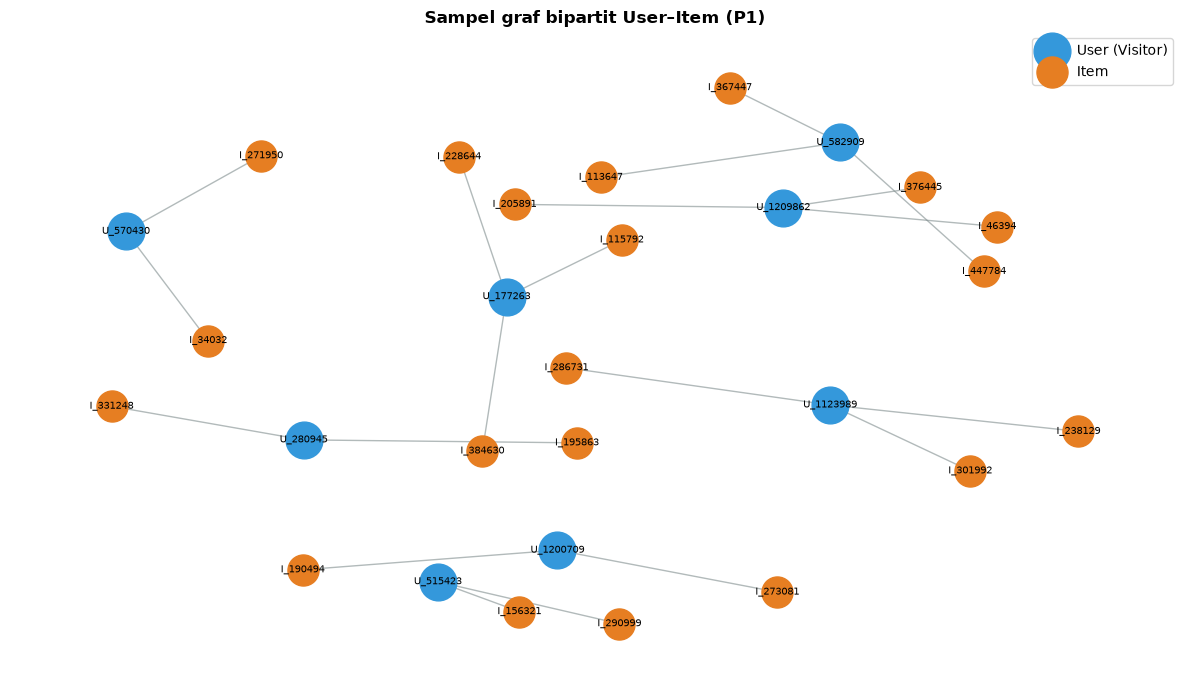

In [9]:
deg_user_df = df_ui.groupby("user").size()
kandidat = deg_user_df[(deg_user_df >= 2) & (deg_user_df <= 4)]
sampel_user = kandidat.sample(min(8, len(kandidat)), random_state=SEED).index
df_sample = df_ui[df_ui["user"].isin(sampel_user)]

B_plot = nx.Graph()
for _, row in df_sample.iterrows():
    B_plot.add_node(f"U_{row['user']}", tipe="User")
    B_plot.add_node(f"I_{row['item']}", tipe="Item")
    B_plot.add_edge(f"U_{row['user']}", f"I_{row['item']}")

pos = nx.spring_layout(B_plot, seed=SEED, k=0.7)
users_n = [n for n, d in B_plot.nodes(data=True) if d["tipe"] == "User"]
items_n = [n for n, d in B_plot.nodes(data=True) if d["tipe"] == "Item"]

plt.figure(figsize=(12, 7))
nx.draw_networkx_nodes(B_plot, pos, nodelist=users_n, node_color="#3498db", node_size=700, label="User (Visitor)")
nx.draw_networkx_nodes(B_plot, pos, nodelist=items_n, node_color="#e67e22", node_size=500, label="Item")
nx.draw_networkx_edges(B_plot, pos, alpha=0.6, edge_color="#7f8c8d")
nx.draw_networkx_labels(B_plot, pos, font_size=7)
plt.title("Sampel graf bipartit User–Item (P1)", fontweight="bold")
plt.legend(loc="upper right"); plt.axis("off"); plt.tight_layout(); plt.show()

**Interpretasi:**

Pada VSM User, setiap user diubah menjadi sebuah vektor. Panjang vektornya sama dengan jumlah item, yaitu 88.699 dimensi, dan nilainya adalah bobot interaksi (view = 1, addtocart = 2, transaction = 3). Kumpulan semua vektor membentuk matriks berukuran 199.899 × 88.699.

Dari sekitar 17,7 miliar sel pada matriks itu, hanya 290.355 sel yang terisi, sehingga sparsity-nya 99,9984 %. Artinya hampir semua isi matriks adalah nol. Hal ini terjadi karena rata-rata user hanya berinteraksi dengan 1,45 item, dan 163.378 user (81,7 %) hanya menyentuh satu item. Karena itu matriks disimpan dalam format sparse (CSR) agar tidak menghabiskan memori.

Plot networkx adalah sampel kecil graf, dengan titik biru sebagai user dan titik oranye sebagai item. Terlihat bahwa tiap user hanya terhubung ke beberapa item saja, sesuai dengan sifat data yang sangat jarang.

### No. 5 — VSM simpul Item

Sekarang sudut pandangnya dibalik: setiap **Item** menjadi vektor sepanjang jumlah user. Cukup dengan **transpos** matriks A, yaitu **Aᵀ** berukuran (jumlah item × jumlah user).

In [10]:
AT = A.T.tocsr()                       # VSM Item: baris = item, kolom = user
n_items_, n_users_ = AT.shape
item_1_user = int((np.diff(AT.indptr) == 1).sum())

display(Markdown(f"""
**Karakteristik VSM simpul Item**

| Karakteristik | Nilai |
|---|---|
| Dimensi tiap vektor item (= jumlah user) | **{fmt(n_users_)}** |
| Shape matriks (item × user) | **({fmt(n_items_)} × {fmt(n_users_)})** |
| Sel terisi (non-zero) | {fmt(AT.nnz)} |
| Sparsity | **{sparsity:.4f} %** (sama, karena hanya transpos) |
| Item yang hanya disentuh 1 user | {fmt(item_1_user)} ({item_1_user / n_items_ * 100:.1f} %) |
"""))


**Karakteristik VSM simpul Item**

| Karakteristik | Nilai |
|---|---|
| Dimensi tiap vektor item (= jumlah user) | **199.899** |
| Shape matriks (item × user) | **(88.699 × 199.899)** |
| Sel terisi (non-zero) | 290.355 |
| Sparsity | **99.9984 %** (sama, karena hanya transpos) |
| Item yang hanya disentuh 1 user | 45.322 (51.1 %) |


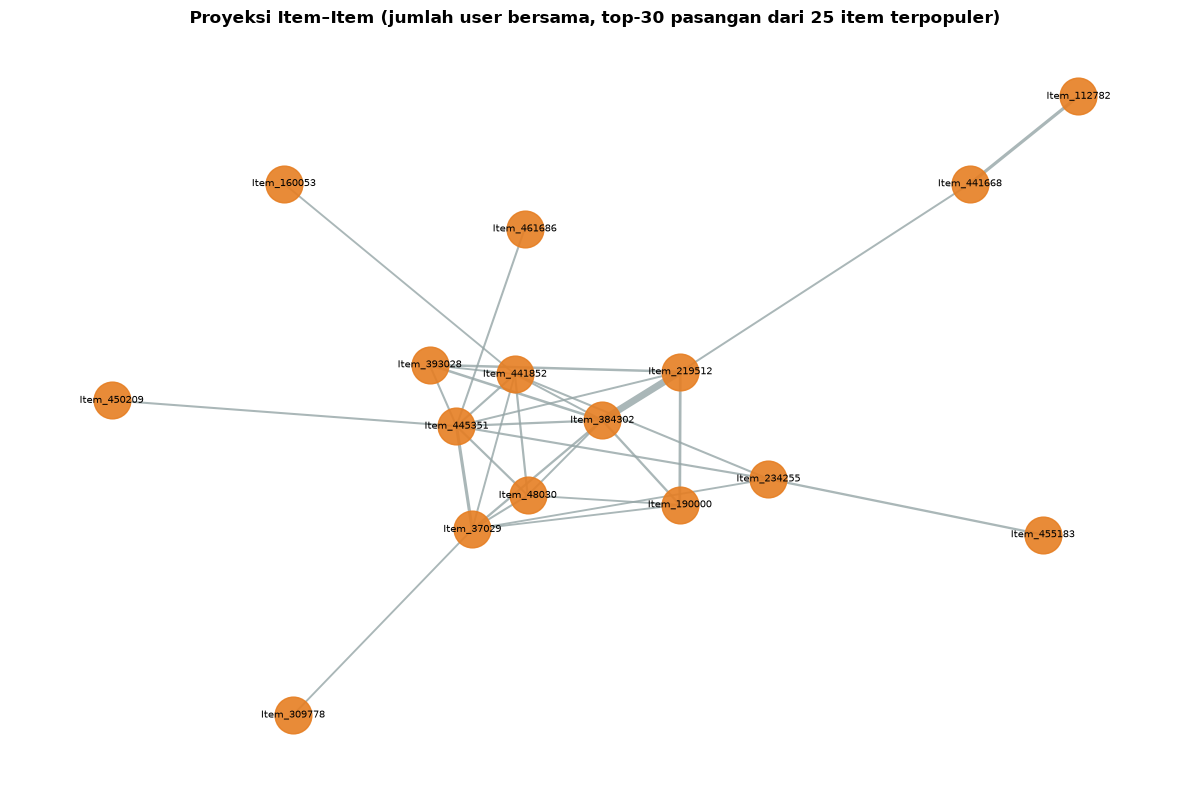

In [11]:
B = A.copy(); B.data[:] = 1            # versi biner (ada/tidak ada interaksi)
d_item = np.asarray(B.sum(axis=0)).ravel().astype(np.int64)   # jumlah user per item
d_user = np.asarray(B.sum(axis=1)).ravel().astype(np.int64)   # jumlah item per user

top_idx = np.argsort(-d_item)[:25]
co = (B[:, top_idx].T @ B[:, top_idx]).toarray()
np.fill_diagonal(co, 0)
pasangan = [(co[a, b], a, b) for a in range(len(top_idx)) for b in range(a + 1, len(top_idx)) if co[a, b] > 0]
pasangan = sorted(pasangan, reverse=True)[:30]

G_item = nx.Graph()
for w, a, b in pasangan:
    G_item.add_edge(f"Item_{i_ids[top_idx[a]]}", f"Item_{i_ids[top_idx[b]]}", weight=int(w))

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_item, seed=SEED, k=0.9)
lebar = [1 + 4 * G_item[u][v]["weight"] / max(1, max(d["weight"] for _, _, d in G_item.edges(data=True))) for u, v in G_item.edges()]
nx.draw_networkx_nodes(G_item, pos, node_color="#e67e22", node_size=700, alpha=0.9)
nx.draw_networkx_edges(G_item, pos, width=lebar, edge_color="#95a5a6", alpha=0.8)
nx.draw_networkx_labels(G_item, pos, font_size=7)
plt.title("Proyeksi Item–Item (jumlah user bersama, top-30 pasangan dari 25 item terpopuler)", fontweight="bold")
plt.axis("off"); plt.tight_layout(); plt.show()

**Interpretasi:**

Pada VSM Item, sudut pandangnya dibalik: setiap item menjadi sebuah vektor yang panjangnya sama dengan jumlah user, yaitu 199.899 dimensi. Matriksnya berukuran 88.699 × 199.899, yaitu hasil transpos dari matriks user–item, sehingga sparsity-nya sama (99,9984 %).

Sebanyak 45.322 item (51,1 %) hanya disentuh oleh satu user, jadi vektor item-item tersebut sangat jarang. Pada plot proyeksi Item–Item, dua item terhubung jika dilihat atau dibeli oleh user yang sama, dan garis yang lebih tebal berarti jumlah user bersamanya lebih banyak. Plot ini hanya menampilkan 25 item terpopuler dan 30 pasangan terkuat supaya gambarnya terbaca.

### No. 6 — Proyeksi mana yang lebih baik?

In [12]:
# Pasangan ko-okurensi (batas atas sisi proyeksi)
pairs_user_proj = int((d_item * (d_item - 1) // 2).sum())
pairs_item_proj = int((d_user * (d_user - 1) // 2).sum())

# Simpul terisolasi di masing-masing proyeksi
coo = B.tocoo()
user_non_iso = np.bincount(coo.row, weights=(d_item[coo.col] > 1), minlength=n_users) > 0
item_non_iso = np.bincount(coo.col, weights=(d_user[coo.row] > 1), minlength=n_items) > 0
iso_user = int((~user_non_iso).sum())
iso_item = int((~item_non_iso).sum())

tabel = pd.DataFrame({
    "Kriteria": ["Jumlah simpul", "Pasangan mungkin (n x n)", "Pasangan ko-okurensi (batas atas sisi)",
                 "Simpul terisolasi", "Persentase terisolasi"],
    "Proyeksi User-User": [fmt(n_users), fmt(n_users ** 2), fmt(pairs_user_proj), fmt(iso_user),
                           f"{iso_user / n_users * 100:.1f} %"],
    "Proyeksi Item-Item": [fmt(n_items), fmt(n_items ** 2), fmt(pairs_item_proj), fmt(iso_item),
                           f"{iso_item / n_items * 100:.1f} %"],
})
display(tabel)

menang_item = sum([
    n_items < n_users,
    n_items ** 2 < n_users ** 2,
    pairs_item_proj < pairs_user_proj,
    iso_item / n_items < iso_user / n_users,
])
pilihan = "Item-Item" if menang_item >= 3 else "User-User"
display(Markdown(f"**Item-Item unggul di {menang_item} dari 4 kriteria, sehingga proyeksi terpilih: {pilihan}.**"))
if pilihan != "Item-Item":
    print("PERHATIAN: hasil data menunjukkan User-User lebih baik. Sesuaikan penjelasan dan bagian similarity/k-NN di bawah.")

,Kriteria,Proyeksi User-User,Proyeksi Item-Item
0,Jumlah simpul,199.899,88.699
1,Pasangan mungkin (n x n),39.959.610.201,7.867.512.601
2,Pasangan ko-okurensi (batas atas sisi),2.386.021,2.022.429
3,Simpul terisolasi,30.861,42.714
4,Persentase terisolasi,15.4 %,48.2 %


**Item-Item unggul di 3 dari 4 kriteria, sehingga proyeksi terpilih: Item-Item.**

**Interpretasi:**

Berdasarkan tabel perbandingan, proyeksi Item–Item dipilih karena lebih ringan. Jumlah simpulnya 88.699 (User–User: 199.899), dan ruang pasangan yang mungkin sekitar 5 kali lebih kecil, yaitu 7,87 miliar dibanding 39,96 miliar. Jumlah pasangan yang benar-benar terbentuk juga lebih sedikit (2.022.429 dibanding 2.386.021), sehingga perhitungannya lebih hemat memori dan waktu.

Meski begitu, proyeksi Item–Item punya kelemahan: 48,2 % itemnya terisolasi (tidak punya tetangga), sedangkan pada user hanya 15,4 %. Item yang terisolasi tidak bisa direkomendasikan lewat kemiripan. Dengan mempertimbangkan kelebihan dan kekurangan tersebut, proyeksi Item–Item tetap dipilih karena unggul pada 3 dari 4 kriteria.

### No. 7 — Perhitungan similarity pada graf terproyeksi (Python)

In [14]:
item_norm = normalize(AT)              # tiap baris item dinormalisasi (panjang 1) -> dot product = cosine

def item_sim(idx):
    """Cosine similarity item ke-idx terhadap SEMUA item (vektor panjang n_items)"""
    return (item_norm @ item_norm[idx].T).toarray().ravel()

anchor_idx = int(np.argmax(d_item))
anchor_id  = int(i_ids[anchor_idx])
print(f"Item acuan: {anchor_id} (dilihat/dibeli {fmt(d_item[anchor_idx])} user di P1)")

sims = item_sim(anchor_idx)
sims[anchor_idx] = -1                                   # jangan hitung dirinya sendiri
urutan = np.lexsort((i_ids, -sims))                     # skor tertinggi dulu; seri -> ID item kecil dulu
top5 = [j for j in urutan[:5] if sims[j] > 0]

df_top_sim = pd.DataFrame({
    "item_acuan": anchor_id,
    "item_mirip": [int(i_ids[j]) for j in top5],
    "skor_cosine": [round(float(sims[j]), 4) for j in top5],
})
print(f"\n=== 5 item paling mirip dengan item {anchor_id} (cosine, dihitung di Python) ===")
print(df_top_sim.to_string(index=False))

Item acuan: 149275 (dilihat/dibeli 474 user di P1)

=== 5 item paling mirip dengan item 149275 (cosine, dihitung di Python) ===
 item_acuan  item_mirip  skor_cosine
     149275       53394       0.0459
     149275      122509       0.0459
     149275      235200       0.0459
     149275      411608       0.0459
     149275          33       0.0325


**Interpretasi:**

Similarity dihitung dengan cosine similarity antar-item. Nilainya 0 sampai 1, dan makin mendekati 1 berarti dua item makin mirip (dilihat atau dibeli oleh user yang mirip). Item acuan yang dipilih adalah item 149275, karena item ini disentuh paling banyak user di P1 (474 user).

Lima item termirip adalah item 53394, 122509, 235200, dan 411608 (masing-masing skor 0,0459), serta item 33 (skor 0,0325). Skornya kecil karena data sangat jarang, sehingga hanya sedikit user yang menyentuh dua item sekaligus. Empat item memiliki skor yang sama, jadi urutannya ditentukan berdasarkan ID item agar hasilnya konsisten setiap dijalankan.


#### No. 7a — Cypher untuk mendapatkan 5 record dengan similarity tertinggi

In [15]:
q_jaccard = """
MATCH (t:Item {itemId: $iid})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WITH t, collect(DISTINCT v) AS vt
UNWIND vt AS v
MATCH (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(o:Item) WHERE o <> t
WITH t, vt, o, count(DISTINCT v) AS irisan
MATCH (o)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(w:Visitor)
WITH t, vt, o, irisan, count(DISTINCT w) AS n_o
RETURN t.itemId AS item_acuan, o.itemId AS item_mirip,
       round(toFloat(irisan) / (size(vt) + n_o - irisan), 4) AS jaccard
ORDER BY jaccard DESC, item_mirip ASC
LIMIT 5
"""
print(run_query(q_jaccard, iid=anchor_id).to_string(index=False))

 item_acuan  item_mirip  jaccard
     149275      235200   0.0082
     149275      339479   0.0054
     149275       91443   0.0039
     149275      317268   0.0039
     149275      139715   0.0036


**Interpretasi:**

Query Cypher ini menghitung kemiripan langsung di dalam Neo4j dengan Jaccard similarity, yaitu jumlah user yang menyentuh kedua item dibagi jumlah user yang menyentuh salah satu item. Hasil teratasnya adalah item 235200 (0,0082), diikuti item 339479 (0,0054), 91443 (0,0039), 317268 (0,0039), dan 139715 (0,0036).

Urutannya berbeda dengan hasil cosine di Python, dan hanya item 235200 yang muncul di kedua daftar. Hal ini wajar karena cosine memakai bobot interaksi (view, addtocart, transaction), sedangkan Jaccard hanya melihat ada atau tidaknya interaksi.

#### No. 7b — Tuliskan kembali nilai similarity ke graf

Skor cosine top-5 disimpan sebagai relasi baru `(:Item)-[:SIMILAR_TO {score}]->(:Item)`. Sebelum menulis, kondisi graf **sebelum** perhitungan disimpan dulu untuk perbandingan di no. 8.

In [16]:
# Foto kondisi SEBELUM menulis relasi similarity
rel_before = run_query("MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY relasi")
graph_before = run_query("""
    MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: $iid})
    RETURN v.visitorId AS user, i.itemId AS item, type(r) AS rel
    ORDER BY user LIMIT 8
""", iid=anchor_id)
print("Relasi di graf SEBELUM similarity:"); print(rel_before.to_string(index=False))

Relasi di graf SEBELUM similarity:
       relasi  jumlah
ADDED_TO_CART    9263
       BOUGHT    3113
       VIEWED  351830


In [17]:
rows = [{"a": int(r.item_acuan), "b": int(r.item_mirip), "score": float(r.skor_cosine)}
        for r in df_top_sim.itertuples()]

driver.execute_query("""
    UNWIND $rows AS row
    MATCH (a:Item {itemId: row.a})
    MATCH (b:Item {itemId: row.b})
    MERGE (a)-[s:SIMILAR_TO]->(b)
    SET s.score = row.score, s.metric = 'cosine'
""", rows=rows, database_=DB)
print("Relasi SIMILAR_TO berhasil ditulis ke graf.\n")

q_cek = """
MATCH (a:Item {itemId: $iid})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY s.score DESC, item_mirip ASC LIMIT 5
"""
print("Hasil query dari graf:")
print(run_query(q_cek, iid=anchor_id).to_string(index=False))

Relasi SIMILAR_TO berhasil ditulis ke graf.

Hasil query dari graf:
 item_acuan  item_mirip  similarity
     149275       53394      0.0459
     149275      122509      0.0459
     149275      235200      0.0459
     149275      411608      0.0459
     149275          33      0.0325


**Interpretasi:**

Lima nilai similarity (cosine) dari item acuan 149275 ditulis ke graf sebagai relasi baru `SIMILAR_TO`, dengan nilai similarity disimpan pada properti `score`. Hasil query dari graf menunjukkan lima relasi tersebut dengan skor yang sama seperti hasil perhitungan di Python, yaitu 0,0459 (empat item) dan 0,0325 (satu item). Artinya penulisan ke graf berhasil dan nilainya konsisten.

### No. 8 — Kondisi graf sebelum dan sesudah perhitungan similarity

**Cypher kondisi SEBELUM**
```cypher
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: <item_acuan>})
RETURN v, r, i LIMIT 10
```
**Cypher kondisi SESUDAH**
```cypher
MATCH (a:Item {itemId: <item_acuan>})-[s:SIMILAR_TO]->(b:Item)
RETURN a, s, b
```

Relasi SEBELUM:
       relasi  jumlah
ADDED_TO_CART    9263
       BOUGHT    3113
       VIEWED  351830

Relasi SESUDAH:
       relasi  jumlah
ADDED_TO_CART    9263
       BOUGHT    3113
   SIMILAR_TO       5
       VIEWED  351830


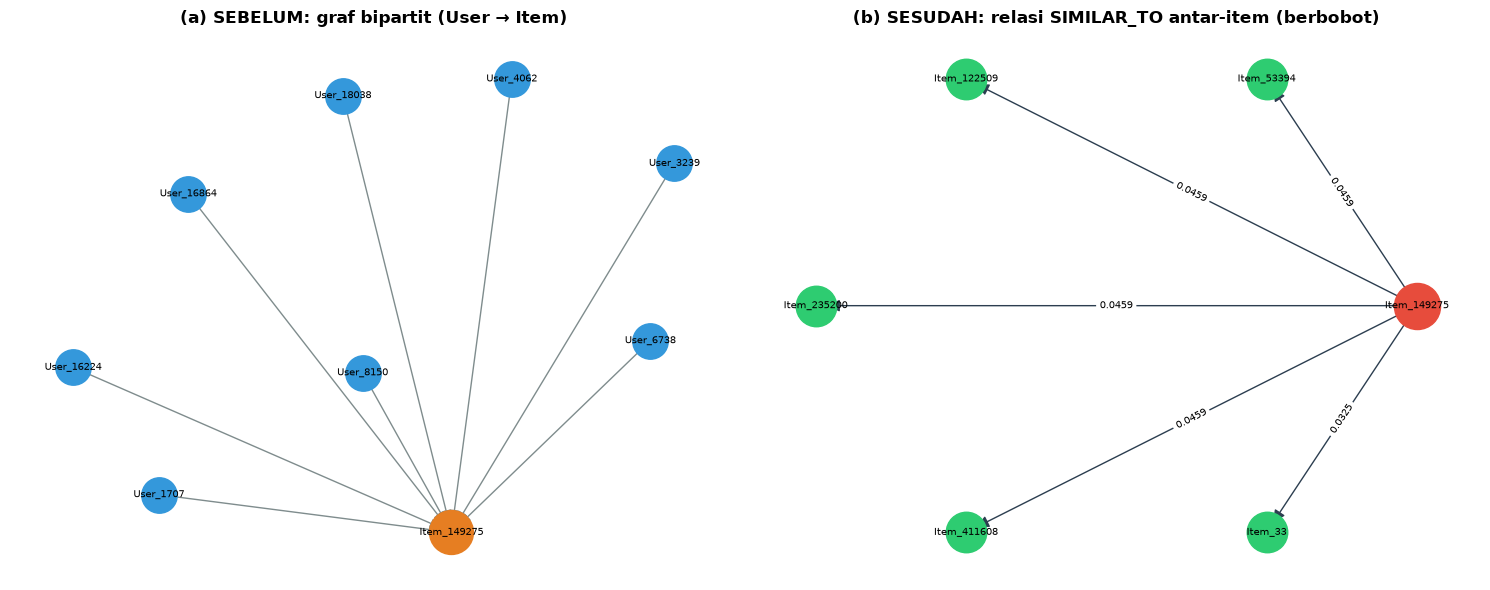

In [18]:
rel_after = run_query("MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY relasi")
graph_after = run_query(q_cek, iid=anchor_id)
print("Relasi SEBELUM:"); print(rel_before.to_string(index=False))
print("\nRelasi SESUDAH:"); print(rel_after.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# (a) SEBELUM
G_b = nx.DiGraph()
for r in graph_before.itertuples():
    G_b.add_edge(f"User_{r.user}", f"Item_{r.item}")
pos_b = nx.spring_layout(G_b, seed=SEED, k=0.8)
item_b = [n for n in G_b if n.startswith("Item_")]
user_b = [n for n in G_b if n.startswith("User_")]
nx.draw_networkx_nodes(G_b, pos_b, nodelist=user_b, node_color="#3498db", node_size=650, ax=axes[0])
nx.draw_networkx_nodes(G_b, pos_b, nodelist=item_b, node_color="#e67e22", node_size=1000, ax=axes[0])
nx.draw_networkx_edges(G_b, pos_b, arrows=True, arrowsize=15, edge_color="#7f8c8d", ax=axes[0])
nx.draw_networkx_labels(G_b, pos_b, font_size=7, ax=axes[0])
axes[0].set_title("(a) SEBELUM: graf bipartit (User → Item)", fontweight="bold"); axes[0].axis("off")

# (b) SESUDAH
G_a = nx.DiGraph()
for r in graph_after.itertuples():
    G_a.add_edge(f"Item_{r.item_acuan}", f"Item_{r.item_mirip}", skor=r.similarity)
pos_a = nx.circular_layout(G_a)
nx.draw_networkx_nodes(G_a, pos_a, nodelist=[f"Item_{anchor_id}"], node_color="#e74c3c", node_size=1100, ax=axes[1])
nx.draw_networkx_nodes(G_a, pos_a, nodelist=[n for n in G_a if n != f"Item_{anchor_id}"], node_color="#2ecc71", node_size=850, ax=axes[1])
nx.draw_networkx_edges(G_a, pos_a, arrows=True, arrowsize=18, edge_color="#2c3e50", ax=axes[1])
nx.draw_networkx_labels(G_a, pos_a, font_size=7, ax=axes[1])
nx.draw_networkx_edge_labels(G_a, pos_a, {(u, v): f"{d['skor']:.4f}" for u, v, d in G_a.edges(data=True)}, font_size=7, ax=axes[1])
axes[1].set_title("(b) SESUDAH: relasi SIMILAR_TO antar-item (berbobot)", fontweight="bold"); axes[1].axis("off")
plt.tight_layout(); plt.show()

**Interpretasi:**

Sebelum perhitungan similarity, graf hanya memiliki tiga jenis relasi dari User ke Item, yaitu VIEWED (351.830), ADDED_TO_CART (9.263), dan BOUGHT (3.113), dengan total 364.206 relasi. Setelah similarity ditulis, muncul jenis relasi baru `SIMILAR_TO` sebanyak 5 yang menghubungkan item acuan 149275 dengan lima item termirip. Relasi yang lama tidak berubah, dan total relasi bertambah menjadi 364.211.

Pada gambar (a), item acuan terhubung ke beberapa user. Pada gambar (b), item acuan terhubung langsung ke item lain dengan garis yang diberi nilai kemiripan. Jadi setelah proses ini, graf tidak hanya menyimpan siapa yang melihat apa, tetapi juga item mana yang mirip dengan item mana.

## 4. Soal 2.2 Analytics

### No. 1 — Memilih user secara acak (reproducible)

In [19]:
seen_by_user = df_ui.groupby("user")["item"].apply(list)          # item yang disentuh user di P1
p2_by_user   = df_p2.groupby("visitorid")["itemid"].apply(set)     # item yang disentuh user di P2
katalog_p1   = set(i_ids)

def item_relevan(user_id):
    """Item P2 yang belum pernah dilihat user di P1 dan ada di katalog P1"""
    return (p2_by_user.get(user_id, set()) - set(seen_by_user[user_id])) & katalog_p1

kandidat_user = [u for u in sorted(overlap_users)                  # <-- DIUBAH (3 baris)
                 if u in seen_by_user.index
                 and len(seen_by_user[u]) >= 2                     # <-- syarat baru: minimal 2 item di P1
                 and len(item_relevan(u)) > 0]

rng = np.random.default_rng(SEED)
chosen_user = int(rng.choice(kandidat_user))

print(f"Visitor di P1 dan P2          : {fmt(len(overlap_users))}")
print(f"Visitor layak dipilih         : {fmt(len(kandidat_user))}")
print(f"Seed                          : {SEED}")
print(f"User terpilih                 : {chosen_user}")
print(f"Item yang disentuh di P1      : {seen_by_user[chosen_user]}")
print(f"Item relevan (kunci jawaban)  : {sorted(item_relevan(chosen_user))}")

Visitor di P1 dan P2          : 6.913
Visitor layak dipilih         : 1.863
Seed                          : 71
User terpilih                 : 1349456
Item yang disentuh di P1      : [426450, 16072]
Item relevan (kunci jawaban)  : [67463]


**Interpretasi:**

User dipilih secara acak memakai `numpy.random.default_rng` dengan seed 71 (dua digit terakhir NIM), sehingga hasilnya selalu sama jika dijalankan ulang. Dari 6.913 visitor yang ada di P1 dan P2, ada 1.863 visitor yang memenuhi syarat, yaitu punya minimal 2 item di P1 dan minimal 1 item baru di P2.

User yang terpilih adalah 1349456. Di P1 ia menyentuh item 16072 dan 426450, dan di P2 ia menyentuh item baru 67463 yang belum pernah ia lihat sebelumnya. Item 67463 inilah yang menjadi kunci jawaban untuk evaluasi.

### No. 1a — Skrip Python rekomendasi k-NN (k = 5)

In [20]:
def rekomendasi_knn(user_id, k=5, top_n=5):
    seen_items = seen_by_user[user_id]
    seen_idx = {item_index[i] for i in seen_items}
    baris_user = user_index[user_id]
    skor = {}
    for idx in seen_idx:
        sims_i = item_sim(idx)
        sims_i[idx] = -1
        tetangga = np.lexsort((i_ids, -sims_i))[:k]                 # k tetangga terdekat
        bobot = A[baris_user, idx]                                   # 1 / 2 / 3
        for j in tetangga:
            if sims_i[j] > 0 and j not in seen_idx:                  # buang item yang sudah pernah dilihat
                skor[j] = skor.get(j, 0.0) + bobot * sims_i[j]
    ranking = sorted(skor.items(), key=lambda x: (-x[1], i_ids[x[0]]))[:top_n]
    return pd.DataFrame({
        "Peringkat": range(1, len(ranking) + 1),
        "Item ID": [int(i_ids[j]) for j, _ in ranking],
        "Skor k-NN": [round(float(s), 4) for _, s in ranking],
    })

df_rec = rekomendasi_knn(chosen_user, k=5, top_n=5)
print(f"=== Top-5 rekomendasi k-NN (k=5) untuk user {chosen_user} ===")
print(df_rec.to_string(index=False))

=== Top-5 rekomendasi k-NN (k=5) untuk user 1349456 ===
 Peringkat  Item ID  Skor k-NN
         1    59953     0.7071
         2   245084     0.5774
         3   179859     0.2887
         4   297875     0.2357
         5   459664     0.2132


**Interpretasi:**

Rekomendasi dibuat dengan item-based k-NN dan k = 5. Caranya: untuk setiap item yang pernah disentuh user, dicari lima item terdekat berdasarkan cosine similarity. Skor tiap item tetangga dihitung dari bobot interaksi user dikali nilai similarity, lalu dijumlahkan. Item yang sudah pernah dilihat user dibuang dari daftar, lalu sisanya diurutkan dari skor tertinggi.

Lima rekomendasi teratas untuk user 1349456 adalah item 59953 (skor 0,7071), 245084 (0,5774), 179859 (0,2887), 297875 (0,2357), dan 459664 (0,2132).

### No. 1b — Tiga item yang diiklankan untuk k = 5

In [21]:
df_iklan = df_rec.head(3)
print(f"=== 3 item yang diiklankan kepada user {chosen_user} (k = 5) ===")
for _, r in df_iklan.iterrows():
    print(f"Iklan {int(r['Peringkat'])}: Item {int(r['Item ID'])}  (skor {r['Skor k-NN']})")

=== 3 item yang diiklankan kepada user 1349456 (k = 5) ===
Iklan 1: Item 59953  (skor 0.7071)
Iklan 2: Item 245084  (skor 0.5774)
Iklan 3: Item 179859  (skor 0.2887)


**Interpretasi:**

Untuk k = 5, tiga item dengan skor tertinggi dipilih untuk diiklankan kepada user 1349456, yaitu item 59953, 245084, dan 179859. Ketiganya berasal dari lima rekomendasi teratas pada no. 1a, dan semuanya adalah item yang belum pernah dilihat oleh user tersebut.

### No. 2 — Evaluasi: Hit@5 dan NDCG@5

In [22]:
def hit_at_k(rec, rel, k=5):
    return 1.0 if any(i in rel for i in rec[:k]) else 0.0

def ndcg_at_k(rec, rel, k=5):
    dcg  = sum(1 / np.log2(r + 2) for r, i in enumerate(rec[:k]) if i in rel)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(rel), k)))
    return dcg / idcg if idcg > 0 else 0.0

rekom  = df_rec["Item ID"].tolist()
relevan = item_relevan(chosen_user)
r_vec  = [1 if i in relevan else 0 for i in rekom]

dcg  = sum(r / np.log2(idx + 2) for idx, r in enumerate(r_vec))
idcg = sum(1 / np.log2(idx + 2) for idx in range(min(len(relevan), 5)))

print(f"User               : {chosen_user}")
print(f"Item rekomendasi   : {rekom}")
print(f"Item relevan (P2)  : {sorted(relevan)}")
print(f"Vektor relevansi   : {r_vec}")
print(f"(a) Hit@5          : {hit_at_k(rekom, relevan):.4f}")
print(f"(b) DCG@5 = {dcg:.5f} | IDCG@5 = {idcg:.5f} | NDCG@5 = {ndcg_at_k(rekom, relevan):.4f}")

User               : 1349456
Item rekomendasi   : [59953, 245084, 179859, 297875, 459664]
Item relevan (P2)  : [67463]
Vektor relevansi   : [0, 0, 0, 0, 0]
(a) Hit@5          : 0.0000
(b) DCG@5 = 0.00000 | IDCG@5 = 1.00000 | NDCG@5 = 0.0000


**Interpretasi:**

Hit@5 bernilai 1 jika minimal satu dari lima rekomendasi ada di kunci jawaban, dan 0 jika tidak ada. NDCG@5 mirip dengan Hit@5, tetapi juga memperhitungkan urutan: item yang benar dan berada di posisi atas mendapat nilai lebih besar.

Untuk user 1349456, kunci jawabannya adalah item 67463, sedangkan lima item yang direkomendasikan adalah 59953, 245084, 179859, 297875, dan 459664. Tidak ada yang cocok, sehingga Hit@5 = 0 dan NDCG@5 = 0 (DCG = 0, IDCG = 1). Ini bukan berarti program salah. Hasil dari satu user sangat dipengaruhi kebetulan, dan jumlah item yang mungkin dilihat user di P2 sangat banyak, sedangkan data latihnya sangat sedikit.

#### (Opsional) Evaluasi pada banyak user
Hasil untuk **satu** user sangat dipengaruhi kebetulan (bisa 0 atau 1). Sel ini menghitung rata-rata Hit@5 dan NDCG@5 pada sampel hingga 200 user (seed sama) sebagai gambaran kualitas sistem yang lebih stabil. Sel ini boleh dilewati jika waktu terbatas.

In [23]:
rng2 = np.random.default_rng(SEED)
n_eval = min(200, len(kandidat_user))
sampel_eval = rng2.choice(kandidat_user, size=n_eval, replace=False)

hits, ndcgs = [], []
for u in tqdm(sampel_eval, desc="Evaluasi banyak user"):
    rec_u = rekomendasi_knn(int(u), k=5, top_n=5)["Item ID"].tolist()
    rel_u = item_relevan(int(u))
    hits.append(hit_at_k(rec_u, rel_u))
    ndcgs.append(ndcg_at_k(rec_u, rel_u))

print(f"Jumlah user dievaluasi : {n_eval}")
print(f"Rata-rata Hit@5        : {np.mean(hits):.4f}")
print(f"Rata-rata NDCG@5       : {np.mean(ndcgs):.4f}")

Evaluasi banyak user:   0%|          | 0/200 [00:00<?, ?it/s]

Jumlah user dievaluasi : 200
Rata-rata Hit@5        : 0.0250
Rata-rata NDCG@5       : 0.0098


**Interpretasi:**

Karena hasil satu user belum bisa mewakili kualitas sistem, evaluasi diulang pada 200 user yang dipilih secara acak dengan seed yang sama. Rata-rata Hit@5 adalah 0,0250 (sekitar 2,5 % user mendapat setidaknya satu rekomendasi yang tepat) dan rata-rata NDCG@5 adalah 0,0098. Nilai ini rendah, tetapi masuk akal karena data sangat jarang dan hanya diambil dari dua minggu aktivitas.

## 5. Kesimpulan dan catatan

Pada UTS ini dibangun sistem rekomendasi berbasis graf memakai Neo4j dan Python dengan data RetailRocket. Data P1 (16–31 Juli 2015) dimasukkan ke Neo4j sebagai graf bipartit berisi 199.899 Visitor, 88.699 Item, dan 364.206 relasi. Matriks interaksinya sangat jarang (sparsity 99,9984 %) karena kebanyakan pengunjung hanya menyentuh satu item.

Proyeksi Item–Item dipilih karena lebih ringan dibanding proyeksi User–User (ruang pasangan sekitar 5 kali lebih kecil), walaupun 48,2 % itemnya terisolasi. Kemiripan item dihitung dengan cosine similarity, lalu lima nilai teratas dari item acuan 149275 ditulis ke graf sebagai relasi `SIMILAR_TO`.

Rekomendasi dibuat dengan item-based k-NN (k = 5). Untuk user 1349456, tiga item yang diiklankan adalah 59953, 245084, dan 179859. Hasil evaluasinya Hit@5 = 0 dan NDCG@5 = 0, sedangkan rata-rata pada 200 user adalah Hit@5 sekitar 0,0250 dan NDCG@5 sekitar 0,0098.

**Keterbatasan:** data sangat jarang, hanya 6.913 visitor yang muncul di P1 dan P2, evaluasi satu user bersifat kebetulan, dan kunci jawaban hanya berasal dari dua minggu data.

**Saran:** memperpanjang periode data, menyaring user yang interaksinya lebih banyak, menambahkan informasi kategori dan properti item, serta mencoba metode gabungan (hybrid).